# Adversarial Attacks

In this notebook, we will be exploring the world of adversarial attacks, where even minor modifications to the input data can cause machine learning models to make incorrect predictions. These attacks illustrate the potential vulnerabilities in systems that rely on machine learning, which raises concerns in fields such as autonomous vehicles. For example, a self-driving car could misinterpret a slightly altered stop sign. We will learn how to create adversarial examples ourselves using the Fast Gradient Sign Method (FGSM).

__Step 1:__ Load the required libraries.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D

:bell: You are free to add any library you deem necessary to successfully complete this homework assignment!  

For this tutorial, we will again use the Cats vs. Dogs dataset, which consists of images featuring the two distinct animal classes. To make data preprocessing easier, we have already organized the images into separate folders. You will find a 'train_dataset' folder containing images used to train your model, a 'validation_dataset' with images for validating your model, and a 'test_dataset' folder with images for testing your model. You can download the preprocessed dataset, [here](https://edubuas-my.sharepoint.com/:f:/g/personal/blerck_i_buas_nl/Egas9AxZzg1MrAE8f8RtErwB1Xy1CKhaNiHQX9hJjTT4Ew?e=WbD2Md). 

__Step 2:__ Download the Cats vs. Dogs dataset, and and assign the paths to the train, validation, and test set folders to the variables ```src_path_train```, ```src_path_validation```, and ```src_path_train```. 

In [3]:
src_path_train = "./cats_and_dogs/train_dataset"
src_path_validation = "./cats_and_dogs/validation_dataset"
src_path_test = "./cats_and_dogs/test_dataset"

__Step 3:__ Pre-process your data: 

- Rescale the images to have pixel values between 0 and 1.
- Resize the images to 224x224 pixels.
- Ensure that the images are in the correct format (e.g., RGB).
- One-hot encode the labels.
- Apply other preprocessing steps, such as horizontal flip and zoom, as necessary. 

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create ImageDataGenerators with augmentation and rescaling
train_datagen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    horizontal_flip=True
)
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Set up generators
train_generator = train_datagen.flow_from_directory(directory=src_path_train,target_size=(224, 224),batch_size=32,class_mode='categorical',   color_mode='rgb',         shuffle=True)

validation_generator = val_test_datagen.flow_from_directory( directory=src_path_validation, target_size=(224, 224),batch_size=32,class_mode='categorical',color_mode='rgb',shuffle=False)

test_generator = val_test_datagen.flow_from_directory(directory=src_path_test,target_size=(224, 224),batch_size=32,class_mode='categorical',color_mode='rgb',shuffle=False)

Found 1668 images belonging to 2 classes.
Found 809 images belonging to 2 classes.
Found 510 images belonging to 2 classes.


__Step 4:__ Split your dataset into an 70% training set, 20% validation set, and 10% test set by assigning the sets to the following variables as a numpy array: ```X_train```, ```X_val```, ```X_test```, ```y_train```, ```y_val```, and ```y_test```.

In [ ]:
import numpy as np

# Helper function to convert generator to numpy arrays
def generator_to_numpy(generator):
    X, y = [], []
    for batch_x, batch_y in generator:
        X.append(batch_x)
        y.append(batch_y)
        if len(X) * generator.batch_size >= generator.samples:
            break
    return np.concatenate(X), np.concatenate(y)
# Convert all datasets
X_train, y_train = generator_to_numpy(train_generator)
X_val, y_val = generator_to_numpy(validation_generator)
X_test, y_test = generator_to_numpy(test_generator)

# Print shapes to verify
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)


X_train: (1668, 224, 224, 3) y_train: (1668, 2)
X_val: (809, 224, 224, 3) y_val: (809, 2)
X_test: (510, 224, 224, 3) y_test: (510, 2)


__Step 5:__ Design a Sequential model using the Keras API. Include at least one Conv2D layer for feature extraction, a Flatten layer to prepare the data for classification, and two Dense layers. Leave the second-to-last Dense layer without an activation function, but apply a softmax activation to the final output layer.

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Create the Sequential model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64),  
    Dense(2, activation='softmax')  
])

# Print model summary
model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 222, 222, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 111, 111, 32)      0         
 D)                                                              
                                                                 
 flatten (Flatten)           (None, 394272)            0         
                                                                 
 dense (Dense)               (None, 64)                25233472  
                                                                 
 dense_1 (Dense)             (None, 2)                 130       
                                                                 
Total params: 25234498 (96.26 MB)
Trainable params: 25234498 (96.26 MB)
Non-trainable params: 0 (0.00 Byte)
____________

__Step 6:__ Compile your model, and train it using the training and validation sets.

In [7]:
# Compile the model
model.compile( optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
# Train the model
history = model.fit( X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=32)



Epoch 1/10


53/53 [==============================] - 19s 348ms/step - loss: 11.1351 - accuracy: 0.5282 - val_loss: 0.7419 - val_accuracy: 0.6069
Epoch 2/10
53/53 [==============================] - 18s 344ms/step - loss: 0.5393 - accuracy: 0.7392 - val_loss: 0.7061 - val_accuracy: 0.6267
Epoch 3/10
53/53 [==============================] - 18s 347ms/step - loss: 0.2855 - accuracy: 0.8933 - val_loss: 0.8386 - val_accuracy: 0.6119
Epoch 4/10
53/53 [==============================] - 18s 338ms/step - loss: 0.1208 - accuracy: 0.9748 - val_loss: 1.1246 - val_accuracy: 0.6193
Epoch 5/10
53/53 [==============================] - 18s 347ms/step - loss: 0.0484 - accuracy: 0.9946 - val_loss: 1.3136 - val_accuracy: 0.6205
Epoch 6/10
53/53 [==============================] - 19s 355ms/step - loss: 0.0190 - accuracy: 0.9988 - val_loss: 1.5054 - val_accuracy: 0.6020
Epoch 7/10
53/53 [==============================] - 19s 358ms/step - loss: 0.0079 - accuracy: 1.0000 - val_loss: 1.5531 - val_accuracy: 0.

__Step 7:__ Load your chosen test image into a NumPy array by setting the index (e.g., ```img = X_test[4]```). Since many XAI techniques expect data in batches, we need to slightly reshape our image to add a batch dimension, even though we are only working with a single image. Use Numpy's [expand_dims()](https://numpy.org/doc/stable/reference/generated/numpy.expand_dims.html) method to add a new dimension at the beginning of your image array. This new dimension represents our batch size of 1, transforming the shape of the array from (224, 224, 3) to (1, 224, 224, 3). Assign the transformed image array to the variable ```img_batch```.  

In [8]:

img = X_test[4]
img_batch = np.expand_dims(img, axis=0)

# Check shape to confirm it's (1, 224, 224, 3)
print("img_batch shape:", img_batch.shape)


img_batch shape: (1, 224, 224, 3)


__Step 8:__ Use your trained model to generate a prediction for the *__original version__* of the chosen image. This prediction be two probabilities (one for each class), in the form of a Numpy array that sum up to 1. Determine which of these two probabilities is higher: The class with the higher probability is the model's initial prediction. Then, save the index of the class with the higher probability in the variable ```initial_class```. Since you only have two classes, this index will be either 0 or 1.

In [9]:

predictions_original = model.predict(img_batch)
initial_class = np.argmax(predictions_original)
# Print results
print("Predicted probabilities:", predictions_original)
print("Initial class prediction:", initial_class)


1/1 [==============================] - 0s 67ms/step
Predicted probabilities: [[8.4106468e-06 9.9999154e-01]]
Initial class prediction: 1


__Step 9:__ Generate the adversarial pattern, and apply the perturbations to the chosen test image by running the next code block. You may adjust the epsilon to change the level of the adversarial perturbation that is added to the original image. 

:bell: If you do not see a heatmap, the vanishing gradient problem might be the culprit. To investigate further, uncomment the ```tf.print(gradient, summarize=-1)``` line within the code block, to see the gradients. For more information on the vanishing gradient problem, see Thursday's independent study material of week 6. 

In [12]:
def create_adversarial_pattern(input_image, input_label):
    input_image = tf.convert_to_tensor(input_image)
    input_label = tf.convert_to_tensor(input_label)

    with tf.GradientTape() as tape:
        tape.watch(input_image)
        prediction = model(input_image)
        loss = tf.keras.losses.categorical_crossentropy(input_label, prediction)
    gradient = tape.gradient(loss, input_image)
    # tf.print(gradient, summarize=-1)  # Uncomment if debugging vanishing gradients
    signed_gradient = tf.sign(gradient)
    return signed_gradient

# Use the original prediction as the label
label = np.array(predictions_original)

# Create perturbation
perturbations = create_adversarial_pattern(img_batch, label)

# Set epsilon (controls strength of attack)
epsilon = 0.3

# Apply perturbation to the original image
img_adversarial = img_batch + epsilon * perturbations

# Clip to maintain valid pixel range
img_adversarial = tf.clip_by_value(img_adversarial, 0, 1)


__Step 10:__ Use your trained model to generate a prediction for the *__adversarial version__* of the chosen image. This prediction be two probabilities (one for each class), in the form of a Numpy array that sum up to 1. Determine which of these two probabilities is higher: The class with the higher probability is the model's initial prediction. Then, save the index of the class with the higher probability in the variable ```adversarial_class```. Since you only have two classes, this index will be either 0 or 1.

In [13]:
# Get prediction on adversarial image
predictions_adversarial = model.predict(img_adversarial)

# Determine the predicted class (0 or 1)
adversarial_class = np.argmax(predictions_adversarial[0])

print("Adversarial prediction:", predictions_adversarial)
print("Adversarial class index:", adversarial_class)


1/1 [==============================] - 0s 27ms/step
Adversarial prediction: [[1. 0.]]
Adversarial class index: 0


__Step 11:__ Run the next code block to visualize the original and adversarial images side-by-side, and see the model's classification results for each. 

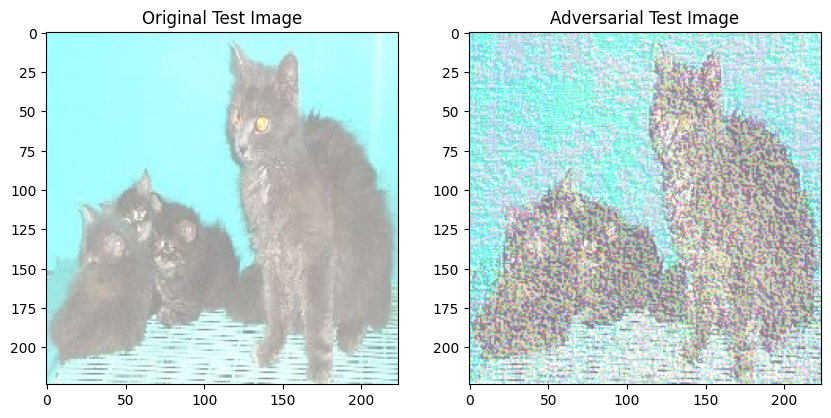

Initial prediction class: 1
[[8.4106468e-06 9.9999154e-01]]
Adversarial prediction class: 0
[[1. 0.]]


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img_batch[0] * 0.5 + 0.5)
ax[0].set_title('Original Test Image')
ax[1].imshow(img_adversarial[0] * 0.5 + 0.5)
ax[1].set_title('Adversarial Test Image')
plt.show()

print(f"Initial prediction class: {initial_class}")
print(predictions_original)
print(f"Adversarial prediction class: {adversarial_class}")
print(predictions_adversarial)